# Synthetic risk model example

**Purpose:** estimate next-period stock covariance and check it against synthetic
data with known conditional covariance. Outputs describe risk; expected-return
predictions belong to other modules.

The example demonstrates the default risk pipeline, covariance accuracy, portfolio
risk calibration, and construction/residual diagnostics. The 15-period evaluation
is illustrative, not empirical validation.

Install with `python -m pip install -e ".[dev]"` from the repository root, then run
all cells using that Python environment.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from risk_model import forecast_risk
from risk_model.diagnostics import (
    compute_bias_statistic,
    diagnose_pure_factor_portfolios,
    diagnose_standardized_residuals,
)
from risk_model.dynamic_risk import estimate_dynamic_variance
from risk_model.factor_model import RiskPanel, fit_factor_model

## 1. Generate inputs and known covariance

**Input:** 260 observations, 20 stocks and seed 23. The generator uses two
industries, two raw styles, unequal market caps and Gaussian shocks with GARCH
variances.

**Output:**

- `panel`: decimal stock returns `(260, 20)`, raw styles `(260, 20, 2)`, industry
  membership and caps `(260, 20)`, plus dates and identifiers.
- `true_covariance`: known conditional stock covariance `(260, 20, 20)`, used only
  for evaluation; it is never passed to the risk model.

Return row `t` uses exposure row `t - 1`; the first row uses the initial exposure.
All panel histories have the same 260 rows.

In [2]:
def make_panel(observations=256, stocks=20, seed=23):
    """Generate Gaussian factor/specific shocks with GARCH variances."""
    rng = np.random.default_rng(seed)
    industries, styles = 2, 2
    membership = np.broadcast_to(
        np.arange(stocks) % industries, (observations, stocks)
    ).copy()
    caps = np.broadcast_to(np.exp(rng.normal(5, 0.5, stocks)), membership.shape).copy()
    raw_styles = rng.normal(size=(observations, stocks, styles))
    dummies = membership[..., None] == np.arange(industries)
    weights = caps[0] / caps[0].sum()
    normalized = (
        raw_styles - np.sum(raw_styles * weights[None, :, None], axis=1, keepdims=True)
    ) / raw_styles.std(axis=1, ddof=1, keepdims=True)
    exposures = np.concatenate(
        (np.ones((observations, stocks, 1)), dummies, normalized), axis=2
    )
    shares = weights @ dummies[0]
    constraint = np.zeros((5, 4))
    constraint[0, 0] = 1
    constraint[1, 1] = 1
    constraint[2, 1] = -shares[0] / shares[1]
    constraint[3:, 2:] = np.eye(styles)
    baseline = np.r_[
        np.array([0.012, 0.007, 0.005, 0.006]) ** 2,
        np.linspace(0.01, 0.018, stocks) ** 2,
    ]
    variance = baseline.copy()
    returns = np.empty((observations, stocks))
    true_covariance = np.empty((observations, stocks, stocks))
    for t in range(observations):
        exposure = exposures[max(t - 1, 0)]
        factor_covariance = (constraint * variance[:4]) @ constraint.T
        true_covariance[t] = (
            exposure @ factor_covariance @ exposure.T + np.diag(variance[4:])
        )
        shocks = rng.normal(size=len(variance)) * np.sqrt(variance)
        returns[t] = exposure @ constraint @ shocks[:4] + shocks[4:]
        variance = 0.05 * baseline + 0.05 * shocks ** 2 + 0.9 * variance
    dates = np.datetime64("2020-01-01") + np.arange(observations)
    panel = RiskPanel(
        dates, np.arange(stocks), returns, raw_styles, np.arange(styles),
        membership, np.arange(industries), caps,
    )
    return panel, true_covariance

In [3]:
panel, true_covariance = make_panel(observations=260, stocks=20, seed=23)
print(
    f"Synthetic panel: {len(panel.dates)} observations, "
    f"{len(panel.asset_ids)} stocks"
)

Synthetic panel: 260 observations, 20 stocks


## 2. Estimate next-period stock covariance

**Input:** `forecast_risk(panel, as_of)` receives the panel and a risk estimation
date, and truncates every input history at that date. Rows 244–258 are the 15
estimation dates; covariance forecasts are evaluated against rows 245–259.

**Calculation:** constrained WLS estimates factor returns and stock residuals.
Eigenfactor-adjusted stable factor covariance is rescaled using Student-t GARCH
factor variances, then combined with exposures and GARCH specific variances.

**Output:** `covariance_forecasts` has shape `(15, 20, 20)`. Diagonal entries are
next-period stock variances; off-diagonal entries are covariances. Units are
squared decimal returns. No expected stock returns are returned.

The optimizer may warn that trial parameters were clipped to allowed bounds.
The fits shown here completed successfully; failed fits raise errors.

In [4]:
risk_origins = range(244, 259)
covariance_forecasts = np.array(
    [forecast_risk(panel, panel.dates[t]) for t in risk_origins]
)
evaluation_rows = np.array(list(risk_origins)) + 1
print(f"Risk estimation dates: {len(covariance_forecasts)}")

C:\Users\62694\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scipy\optimize\_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)


C:\Users\62694\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scipy\optimize\_slsqp_py.py:441: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  g = append(wrapped_grad(x), 0.0)
C:\Users\62694\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scipy\optimize\_slsqp_py.py:501: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  a_ieq = vstack([con['jac'](x, *con['args'])


Risk estimation dates: 15


## 3. Evaluate covariance accuracy and risk calibration

**Input:** align each covariance forecast with the next row's known covariance
and realized returns. The equal-weight portfolio's returns and variances are
computed here as $w^T r$ and $w^T\Sigma w$ before calling the bias diagnostic.

**Outputs and interpretation:**

| Printed result | Meaning |
|---|---|
| Mean relative Frobenius error | Average $\|\widehat\Sigma-\Sigma_{\mathrm{true}}\|_F/\|\Sigma_{\mathrm{true}}\|_F$ across dates; zero means exact covariance recovery. |
| Mean stock risk bias | Average of the 20 individual-stock bias statistics. |
| Equal-weight portfolio risk bias | One bias statistic for a portfolio holding 5% in each stock. |
| Mean eigenfactor risk bias | Average bias across portfolios defined by each covariance forecast's eigenvectors, ordered by eigenvalue. |

For each scored series, **risk bias** is the sample standard deviation of
$r_t/\sqrt{v_t}$ across the 15 evaluation dates, using each date's predicted
variance. One indicates matching risk scale; above one suggests underestimated
risk, below one suggests overestimated risk. This is not bias in predicted
returns. Averages can hide individual mismatches, and 15 observations are noisy.

In [5]:
relative_error = np.linalg.norm(
    covariance_forecasts - true_covariance[evaluation_rows], axis=(1, 2)
)
relative_error /= np.linalg.norm(true_covariance[evaluation_rows], axis=(1, 2))
stock_bias = compute_bias_statistic(
    panel.returns[evaluation_rows], covariance_forecasts
)
weights = np.full(len(panel.asset_ids), 1 / len(panel.asset_ids))
portfolio_returns = panel.returns[evaluation_rows] @ weights
portfolio_variances = np.einsum("i,tij,j->t", weights, covariance_forecasts, weights)
portfolio_bias = compute_bias_statistic(portfolio_returns, portfolio_variances)
eigen_bias = compute_bias_statistic(
    panel.returns[evaluation_rows], covariance_forecasts, eigenfactor=True
)
print(f"Mean relative Frobenius error: {relative_error.mean():.4f}")
print(f"Mean stock risk bias: {stock_bias.mean():.4f}")
print(f"Equal-weight portfolio risk bias: {portfolio_bias:.4f}")
print(f"Mean eigenfactor risk bias: {eigen_bias.mean():.4f}")

Mean relative Frobenius error: 0.1756
Mean stock risk bias: 0.9021
Equal-weight portfolio risk bias: 0.9593
Mean eigenfactor risk bias: 1.0003


## 4. Customize selected methods

All calls use the same final risk estimation date and return `(20, 20)` stock
covariance. Options follow SPEC order: stable risk → dynamic risk → integration.
Omitted dictionary entries keep defaults. Shrinkage uses `None` to disable
and `{}` to enable defaults. `integration_method` selects `"rescale"` (default)
or `"blend"`; inactive settings are ignored. In rescaling mode,
`rescaling_level` accepts `"factor"` or `"stock"`.

**Stable risk.**

For factor-model correlation/targets or factor blending, `factor_covariance`
accepts `eigenfactor_adjustment=True`, `simulations=1000` (positive integer draws)
and `a=1.0` (positive correction-strength multiplier). Set
`factor_covariance={"eigenfactor_adjustment": False}` for sample factor covariance;
then `simulations` and `a` are ignored. These settings are entirely ignored when
no stable factor covariance is used, such as the Ledoit-Wolf example below.

**L7 stable covariance blending (shrinkage).** The example first estimates stable stock
covariance with Ledoit-Wolf, then uses its average pairwise correlation and
EWMA stock volatilities. Stable shrinkage and correlation construction can be
combined before dynamic rescaling. Stock shrinkage is off by default;
with stock rescaling, `covariance_shrinkage={}` selects `factor_model` and `w=0.5`.

| `covariance_shrinkage["method"]` | Target | Weight |
|---|---|---|
| `"factor_model"` (default method when used) | Stable factor-model stock covariance | `w=0.5` |
| `"scaled_identity"` | Mean sample variance times identity | `w=0.5` |
| `"constant_correlation"` | Sample variances with average pairwise correlation | `w=0.5` |
| `"ledoit_wolf"` | Scaled identity | Fitted automatically; ignores `w` |

`w` is target weight in `[0, 1]`: `0` retains sample covariance, `1` selects the
target. Use, for example, `covariance_shrinkage={"method": "factor_model", "w": 0.3}`
with `rescaling_level="stock"`. Targets and return histories are supplied internally.
L7 blends sample and target matrices of shape `(N,N)`, with the factor-model
stock covariance as the default target. Its `(N,N)` output is not consumed by
factor rescaling or L8 factor blending, so this setting is ignored in those calculations.

`specific_shrinkage={}` applies Bayesian shrinkage with `q=1.0` to the **stable**
specific baseline, before blending or building a stock factor-model target.
It needs at least ten stocks; `q >= 0`, and `q=0` leaves the baseline unchanged.
The setting is ignored when no stable specific baseline is used. It never
shrinks dynamic variances directly.

In [6]:
as_of = panel.dates[risk_origins[-1]]
shrunk_covariance = forecast_risk(
    panel, as_of,
    covariance_shrinkage={"method": "ledoit_wolf"},
    dynamic_variance={"method": "ewma"},
    rescaling_level="stock",
    rescaling={"method": "constant_correlation"},
)

**Dynamic risk — EWMA.** This example changes factor and residual variances
to EWMA with decay `0.97`, and uses constant correlation between factors.

| `dynamic_variance["method"]` | Parameters |
|---|---|
| `"garch"` (default) | GARCH(1,1); `distribution="student_t"` or `"gaussian"` |
| `"arch"` | ARCH(1); same distributions, Student-t by default |
| `"ewma"` | `lambda_=0.94`, with `0 < lambda_ < 1`; larger means slower decay |

Only EWMA uses `lambda_`; only ARCH/GARCH use `distribution`. Recognized
parameters irrelevant to the chosen method are ignored, so
`dynamic_variance={"method": "ewma"}` works alone. Means, ARCH/GARCH coefficients
and Student-t degrees of freedom are fitted internally. The chosen settings apply
to factors and residuals with factor rescaling, or to stock returns with stock
rescaling. Here `rescaling_level` remains its default `"factor"`.

In [7]:
ewma_covariance = forecast_risk(
    panel, as_of,
    dynamic_variance={"method": "ewma", "lambda_": 0.97},
    rescaling={"method": "constant_correlation"},
)

**L8 dynamic integration — choose rescaling or blending.** With
`integration_method="rescale"`, the default `rescaling_level="factor"` uses
factor covariance `(K,K)` and forecast factor variances `(K,)`, then assembles
stock covariance with dynamic specific variances `(N,)`. `"stock"` uses stable
stock covariance `(N,N)` and forecast stock variances `(N,)` directly.

| `rescaling["method"]` | Correlation construction before rescaling |
|---|---|
| `"factor_model"` (default) | Preserve correlation from the stable factor-model estimate |
| `"historical_average"` | Preserve historical sample correlation |
| `"constant_correlation"` | Use average pairwise correlation |
| `"shrinkage"` | Shrink correlation toward identity; `w=0.5` in `[0, 1]` |

Only correlation shrinkage uses rescaling's `w`. During **stock rescaling**,
an enabled covariance-shrinkage estimate supplies the input to these constructions; the
first two preserve its correlation. Thus stable covariance shrinkage and a
correlation adjustment may precede the same dynamic rescaling step.

With `integration_method="blend"`, L8 blends stable and dynamic **factor covariance**
and **specific variances**, then assembles stock covariance. The dynamic factor
input uses forecast factor volatilities and fixed stable factor correlation
(L8 slide 52). Its construction uses the rescaling formula internally, but the
final estimator is a weighted average, not the standalone rescaling estimator.

`factor_blending` and `specific_blending` use `stable_weight=0.5` when omitted,
`None` or `{}`. Weights lie in `[0, 1]`: `0` selects dynamic risk, `1` stable risk.
Specific blending also accepts an `(N,)` array of per-stock weights.
Rescaling-only settings are ignored in blending mode; blend weights are ignored
in rescaling mode. A blend-weight dictionary alone no longer selects blending.

The example explicitly selects blending, gives stable factor covariance 30%
weight, and uses the default 50/50 specific blend with a Bayesian stable baseline.

In [8]:
blended_covariance = forecast_risk(
    panel, as_of,
    specific_shrinkage={},
    dynamic_variance={"method": "ewma"},
    integration_method="blend",
    factor_blending={"stable_weight": 0.3},
    specific_blending={},
)

**Read the results:** compare the equal-weight portfolio's predicted volatility
for the next observation interval. Differences show how the choices affect risk
estimates; lower volatility does not mean a better estimator. The earlier 15-date
accuracy and bias results still describe only the default model.

In [9]:
for label, covariance in (
    ("Default", covariance_forecasts[-1]),
    ("Stock EWMA / shrinkage + constant correlation", shrunk_covariance),
    ("EWMA / constant correlation", ewma_covariance),
    ("Factor EWMA / blending", blended_covariance),
):
    volatility = np.sqrt(weights @ covariance @ weights)
    print(f"{label}: {volatility:.2%}")

Default: 1.36%
Stock EWMA / shrinkage + constant correlation: 1.28%
EWMA / constant correlation: 1.36%
Factor EWMA / blending: 1.31%


## 5. Check pure factor portfolio construction

**Input:** fit the full panel to obtain factor returns, stock residuals, exposures
and pure factor portfolio weights. The diagnostic reads returns, caps and industry
information from `panel`, and holdings, exposures and factor returns from
`factor_result`.

**Output:** three maximum absolute algebraic errors:

- **Return replication:** holdings applied to next-row stock returns reproduce
  estimated factor returns.
- **Exposure structure:** portfolio exposures match the constrained factor
  structure, including industry cap shares.
- **Weight sums:** country-portfolio weights sum to one; industry/style weights
  sum to zero.

Near-zero errors confirm these construction identities. These full-history checks
do not measure out-of-sample risk accuracy.

In [10]:
factor_result = fit_factor_model(panel)
algebra = diagnose_pure_factor_portfolios(panel, factor_result)
labels = ("Return replication", "Exposure structure", "Weight sums")
for label, error in zip(labels, algebra):
    print(f"{label}: {error:.3e}")

Return replication: 0.000e+00
Exposure structure: 7.272e-15
Weight sums: 3.851e-15


## 6. Inspect the fitted volatility model

**Input:** the 259 estimated country-factor returns (the first factor column).
Default Student-t GARCH fitting returns next-period variance, standardized
residuals and fitted degrees of freedom. The diagnostic uses the latter two:
each residual is a fitted-mean innovation divided by fitted conditional volatility.

**Output:** one three-panel figure:

- **Residual ACF:** nonzero-lag correlations indicate remaining serial dependence.
- **Squared-residual ACF:** nonzero-lag correlations indicate remaining volatility
  dependence. Lag zero is always one in both ACF plots.
- **Q-Q plot:** closeness to the line indicates agreement with the fitted
  unit-variance Student-t distribution; tail departures highlight tail mismatch.

The annotated mean and variance should be near zero and one. These are in-sample
checks; individual spikes alone do not establish model failure.

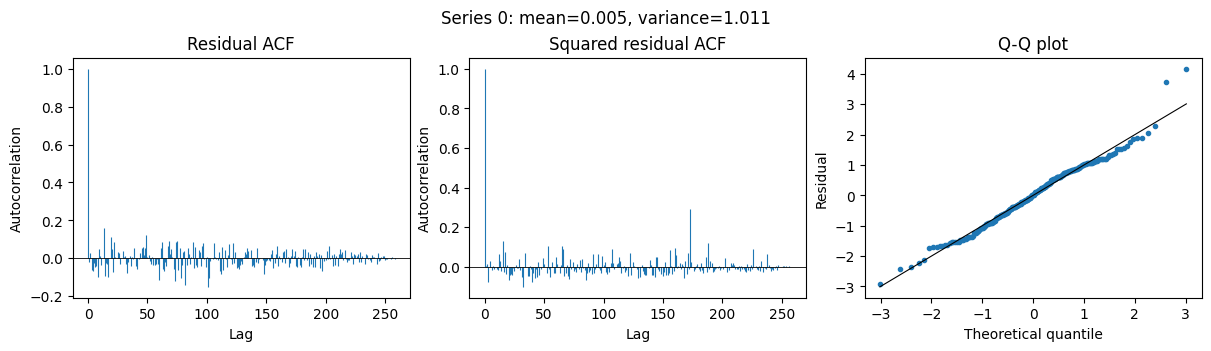

In [11]:
dynamic = estimate_dynamic_variance(factor_result.factor_returns[:, :1])
figures = diagnose_standardized_residuals(
    dynamic.standardized_residuals, dynamic.degrees_of_freedom
)
plt.show()